In [99]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Vérification des doublons

In [39]:
# Nombre de lignes dupliquées
nb_doublons = df.duplicated().sum()

print("Nombre de lignes dupliquées :", nb_doublons)

Nombre de lignes dupliquées : 0


#### Okk, il n'y a pas de doublons

# Affichage de quelques données de la base

In [32]:
# Afficher les noms des colonnes
for i, col in enumerate(df.columns):
    print(i, col)

0 Patient_ID
1 Chip_Type
2 Age
3 Gender
4 Blood_Month_sample
5 French_Residence_Department
6 French_Region
7 Rural_or_urban_area
8 Sensitization
9 Treatment_of_rhinitis
10 Treatment_of_athsma
11 Age_of_onsets
12 Skin_Symptoms
13 General_cofactors
14 Treatment_of_atopic_dematitis
15 Act_d_1
16 Act_d_2
17 Act_d_5
18 Act_d_8
19 Aln_g_1
20 Alt_a_1
21 Alt_a_6
22 Amb_a_1
23 Ana_o_2
24 Ani_s_1
25 Ani_s_3
26 Api_g_1
27 Api_m_1
28 Api_m_4
29 Ara_h_1
30 Ara_h_2
31 Ara_h_3
32 Ara_h_6
33 Ara_h_8
34 Ara_h_9
35 Art_v_1
36 Art_v_3
37 Asp_f_1
38 Asp_f_3
39 Asp_f_6
40 Ber_e_1
41 Bet_v_1
42 Bet_v_2
43 Bet_v_4
44 Bla_g_1
45 Bla_g_2
46 Bla_g_5
47 Bla_g_7
48 Blo_t_5
49 Bos_d_4
50 Bos_d_5
51 Bos_d_6
52 Bos_d_8
53 Bos_d_Lactoferrin
54 Can_f_1
55 Can_f_2
56 Can_f_3
57 Can_f_5
58 Che_a_1
59 Cla_h_8
60 Cor_a_1.0101
61 Cor_a_1.0401
62 Cor_a_8
63 Cor_a_9
64 Cry_j_1
65 Cup_a_1
66 Cyn_d_1
67 Der_f_1
68 Der_f_2
69 Der_p_1
70 Der_p_10
71 Der_p_2
72 Equ_c_1
73 Equ_c_3
74 Fag_e_2
75 Fel_d_1
76 Fel_d_2
77 Fel_d_4
78 Gad

In [36]:
df.head()

,Patient_ID,Chip_Type,Age,Gender,Blood_Month_sample,French_Residence_Department,French_Region,Rural_or_urban_area,Sensitization,Treatment_of_rhinitis,...,Man_i,Mel_g,Mes_a_1_RUO,Mor_r,Mus_a,Myt_e,Ole_e_7_RUO,Ori_v,Ory_c_1,Ory_c_2
0,FHB0001,ISAC_V1,21.0,1.0,11.0,deptY,regionB,9,1,9.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,FHB0002,ISAC_V1,45.0,0.0,12.0,deptY,regionB,9,1,9.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,FHB0003,ISAC_V1,18.0,1.0,1.0,deptY,regionB,9,0,2.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,FHB0004,ISAC_V1,19.0,0.0,1.0,deptY,regionB,9,1,9.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,FHB0005,ISAC_V1,28.0,0.0,1.0,deptY,regionB,9,1,9.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


# Type des différentes variables

In [44]:
df = pd.read_csv(
    "data.csv",
    sep=";",
    encoding="utf-8-sig",   # -sig supprime le BOM proprement
    decimal=",",
    low_memory=False
)

print("dimensions des données :")
print("Nombre de variables :", df.shape[1])
print("Nombre de patients :", df.shape[0])
print("Nombre de variables par type :")
print(df.dtypes.value_counts())

dimensions des données :
Nombre de variables : 256
Nombre de patients : 4271
Nombre de variables par type :
float64    245
object       8
int64        3
Name: count, dtype: int64


**Type float64 : Nombres décimaux**

**Type object : Texte ou données de type hétérogènes**

**type int64 : Nombre entiers**

In [28]:
# Afficher les variables de type object
print("Variables de Type object :")
for i, col in enumerate(df.select_dtypes(include="object").columns):
    print(col)

# Afficher les variables de type int64
print()
print("Variables de Type int64 :")
for i, col in enumerate(df.select_dtypes(include="int64").columns):
    print(col)

Variables de Type object :
Patient_ID
Chip_Type
French_Residence_Department
French_Region
Treatment_of_athsma
Age_of_onsets
General_cofactors
Treatment_of_atopic_dematitis

Variables de Type int64 :
Rural_or_urban_area
Sensitization
Skin_Symptoms


# Vérification des données non renseignées (généralement repérées dans la base par "9")

In [47]:
# Nombre de valeurs égales à 9 pour chaque variable
nb_9 = (df == 9).sum()

# Afficher uniquement les variables contenant au moins un 9
nb_9 = nb_9[nb_9 > 0].sort_values(ascending=False)

print(nb_9)

Rural_or_urban_area      2980
Treatment_of_rhinitis    2958
Skin_Symptoms            2445
Blood_Month_sample        300
Age                       157
Der_f_2                     2
Phl_p_1                     2
Ara_h_2                     1
Cor_a_8                     1
Der_p_2                     1
Hev_b_8                     1
Ole_e_1                     1
Pla_a_3                     1
Act_d_10                    1
dtype: int64


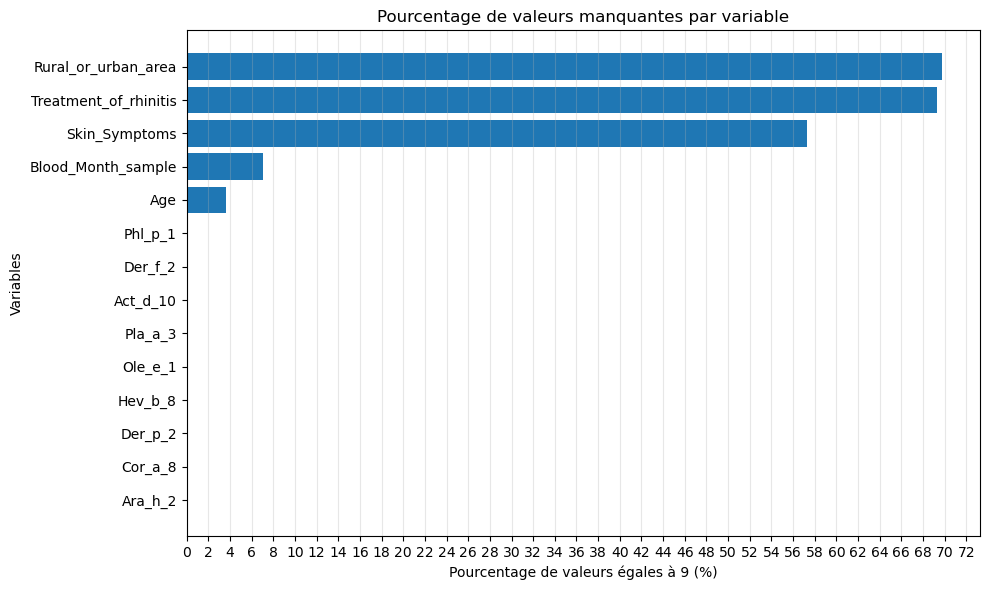

In [105]:
# Pourcentage de valeurs égales à 9 par variable
pourcentage_9 = (df == 9).mean() * 100

# On conserve uniquement les variables contenant des 9
pourcentage_9 = pourcentage_9[pourcentage_9 > 0].sort_values()

# Graphique
plt.figure(figsize=(10, max(6, len(pourcentage_9) * 0.25)))

plt.barh(pourcentage_9.index, pourcentage_9.values)

plt.xlabel("Pourcentage de valeurs égales à 9 (%)")
plt.ylabel("Variables")
plt.title("Pourcentage de valeurs manquantes par variable")

plt.gca().xaxis.set_major_locator(plt.MultipleLocator(2))
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

- "Age" : Patients âgés de 9 ans --> **faux problème**

- "Blood_Month_Sample" : Patients avec un prélèvement sanguin en Septembre --> **faux problème**

- "Rural_or_urban_area" a effectivement un fort taux de valeurs non renseignées --> **69,8%**

- Pour "Treatement_of_rhinitis", il s'agit aussi valeurs non renseignées --> **69,3%**

**- Pour "Skin_Symptoms", il s'agit des patients dont cette variable est "Not relevant" donc sans objet c'est-à-dire que la question du symptôme ne se pose pas pour cette personne --> 57,2%**

# Vérification des véritables NaN

In [121]:
print("Nombre total de NaN :", df.isna().sum().sum())
print("Pourcentage global de NaN dans la base de données :",
      round(df.isna().sum().sum() / df.size * 100, 2), "%")
print()

# Nombre de valeurs manquantes (NaN) par variable
nb_nan = df.isna().sum()

# Afficher uniquement les variables ayant au moins un NaN
nb_nan = nb_nan[nb_nan > 0].sort_values(ascending=False)

print("Nombre de Nan par variables :")
print(nb_nan)

Nombre total de NaN : 424778
Pourcentage global de NaN dans la base de données : 38.85 %

Nombre de Nan par variables :
Hev_b_6               3490
Alpha-Gal             3490
Chi_spp.              3132
Fel_d_7               3132
Equ_c_4               3132
                      ... 
Pol_d_5                781
Ves_v_5                781
Blood_Month_sample     125
Gender                  62
Age                     61
Length: 153, dtype: int64


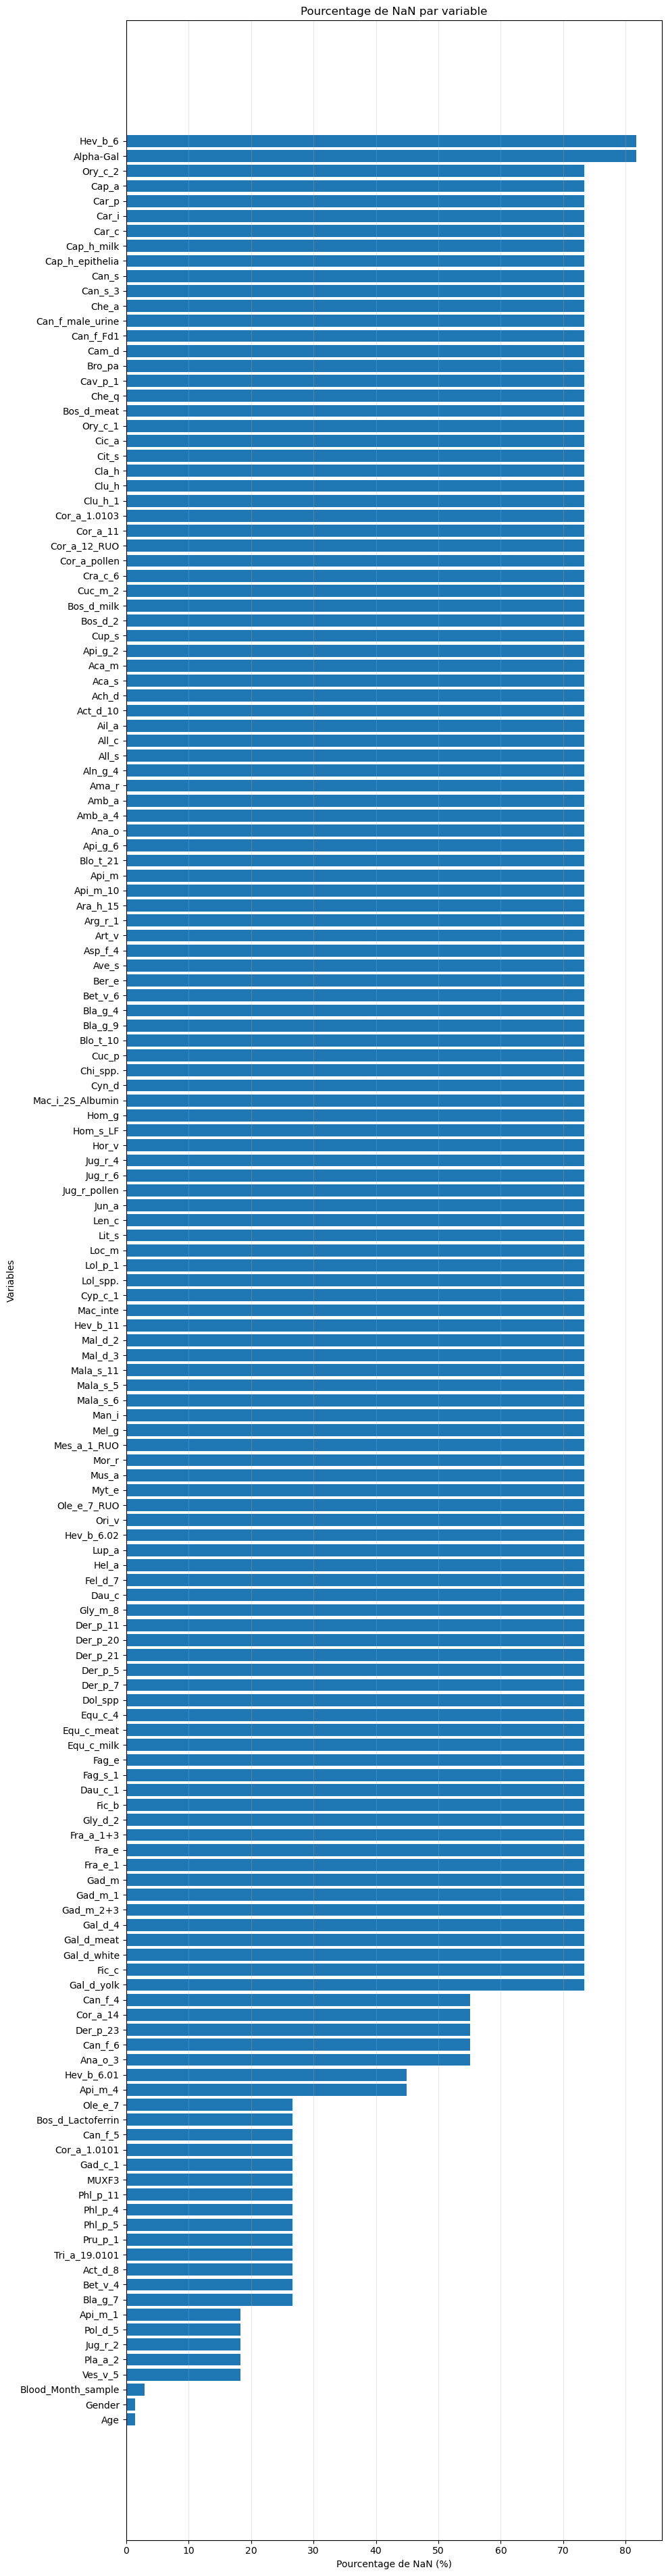

In [117]:
# Pourcentage de valeurs manquantes par variable
pourcentage_nan = df.isna().mean() * 100

# On conserve uniquement les variables concernées
pourcentage_nan = pourcentage_nan[pourcentage_nan > 0].sort_values()

# Graphique
plt.figure(figsize=(10, max(6, len(pourcentage_nan) * 0.25)))

plt.barh(pourcentage_nan.index, pourcentage_nan.values)

plt.xlabel("Pourcentage de NaN (%)")
plt.ylabel("Variables")
plt.title("Pourcentage de NaN par variable")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [145]:
# Nombre total de cellules par puce
nb_cellules_chip = df.groupby("Chip_Type").apply(
    lambda groupe: groupe.size
)

# Nombre de NaN par puce
nb_nan_chip = df.groupby("Chip_Type").apply(
    lambda groupe: groupe.isna().sum().sum()
)

# Pourcentage de NaN par puce
pourcentage_nan_chip = nb_nan_chip / nb_cellules_chip * 100

# Tableau récapitulatif
resume_nan_chip = pd.DataFrame({
    "Nombre de cellules": nb_cellules_chip,
    "Nombre de NaN": nb_nan_chip,
    "Pourcentage de NaN (%)": pourcentage_nan_chip.round(2)
})

display(resume_nan_chip)

/var/folders/rf/2dg4gg8x7hqbtgrbrmjg40b40000gn/T/ipykernel_22707/2984355406.py:2: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  nb_cellules_chip = df.groupby("Chip_Type").apply(
/var/folders/rf/2dg4gg8x7hqbtgrbrmjg40b40000gn/T/ipykernel_22707/2984355406.py:7: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  nb_nan_chip = df.groupby("Chip_Type").apply(


,Nombre de cellules,Nombre de NaN,Pourcentage de NaN (%)
Chip_Type,,,
ALEX,291584,20566,7.05
ISAC_V1,601856,303280,50.39
ISAC_V2,199936,100932,50.48


#### À regarder : Est-ce que les puces "ISAC_V1" et "ISAC_V2" mesurent plutôt les variables où les pourcentages de NaN sont élevés ? Ou est-ce que les 3 puces mesurent les mêmes variables ?

# Échelle des variables cliniques 
#### (15 premières colonnes en ne prenant que les variables numériques)

In [161]:
# Statistiques descriptives des 15 premières variables numériques
stats = df.iloc[:, :15].describe().T

display(stats)

,count,mean,std,min,25%,50%,75%,max
Age,4210.0,23.077435,18.633354,0.0,9.0,16.0,35.0,102.0
Gender,4209.0,0.508197,0.499992,0.0,0.0,1.0,1.0,1.0
Blood_Month_sample,4146.0,6.385191,3.418881,1.0,3.0,7.0,9.0,12.0
Rural_or_urban_area,4271.0,6.505736,3.797497,0.0,1.0,9.0,9.0,9.0
Sensitization,4271.0,0.837977,0.368515,0.0,1.0,1.0,1.0,1.0
Treatment_of_rhinitis,4271.0,6.442590,3.883842,0.0,2.0,9.0,9.0,9.0
Skin_Symptoms,4271.0,5.419106,4.156195,0.0,1.0,9.0,9.0,9.0


# Distribution des grandeurs

In [171]:
# Sélection des variables numériques
df_num = df.select_dtypes(include="number")

# Calcul des indicateurs
distribution = pd.DataFrame({
    "Moyenne": df_num.mean(),
    "Écart-type": df_num.std(),
    "Asymétrie": df_num.skew(),
    "Min": df_num.min(),
    "Q1 (25%)": df_num.quantile(0.25),
    "Médiane (50%)": df_num.median(),
    "Q3 (75%)": df_num.quantile(0.75),
    "Max": df_num.max()
})

display(distribution.head(15).round(3))

,Moyenne,Écart-type,Asymétrie,Min,Q1 (25%),Médiane (50%),Q3 (75%),Max
Age,23.077,18.633,1.008,0.0,9.0,16.0,35.0,102.00
Gender,0.508,0.500,-0.033,0.0,0.0,1.0,1.0,1.00
Blood_Month_sample,6.385,3.419,0.045,1.0,3.0,7.0,9.0,12.00
Rural_or_urban_area,6.506,3.797,-0.875,0.0,1.0,9.0,9.0,9.00
Sensitization,0.838,0.369,-1.835,0.0,1.0,1.0,1.0,1.00
Treatment_of_rhinitis,6.443,3.884,-0.901,0.0,2.0,9.0,9.0,9.00
Skin_Symptoms,5.419,4.156,-0.311,0.0,1.0,9.0,9.0,9.00
Act_d_1,0.536,3.247,11.133,-1.0,0.0,0.0,0.0,72.14
Act_d_2,0.342,2.545,21.244,-1.0,0.0,0.0,0.0,91.64
Act_d_5,0.007,0.105,21.524,0.0,0.0,0.0,0.0,3.30


**Asymétrie :**

**Proche de 0 -->Distribution relativement symétrique**

**Positive --> Queue plus étendue vers les grandes valeurs**

**Négative --> Queue plus étendue vers les petites valeurs**

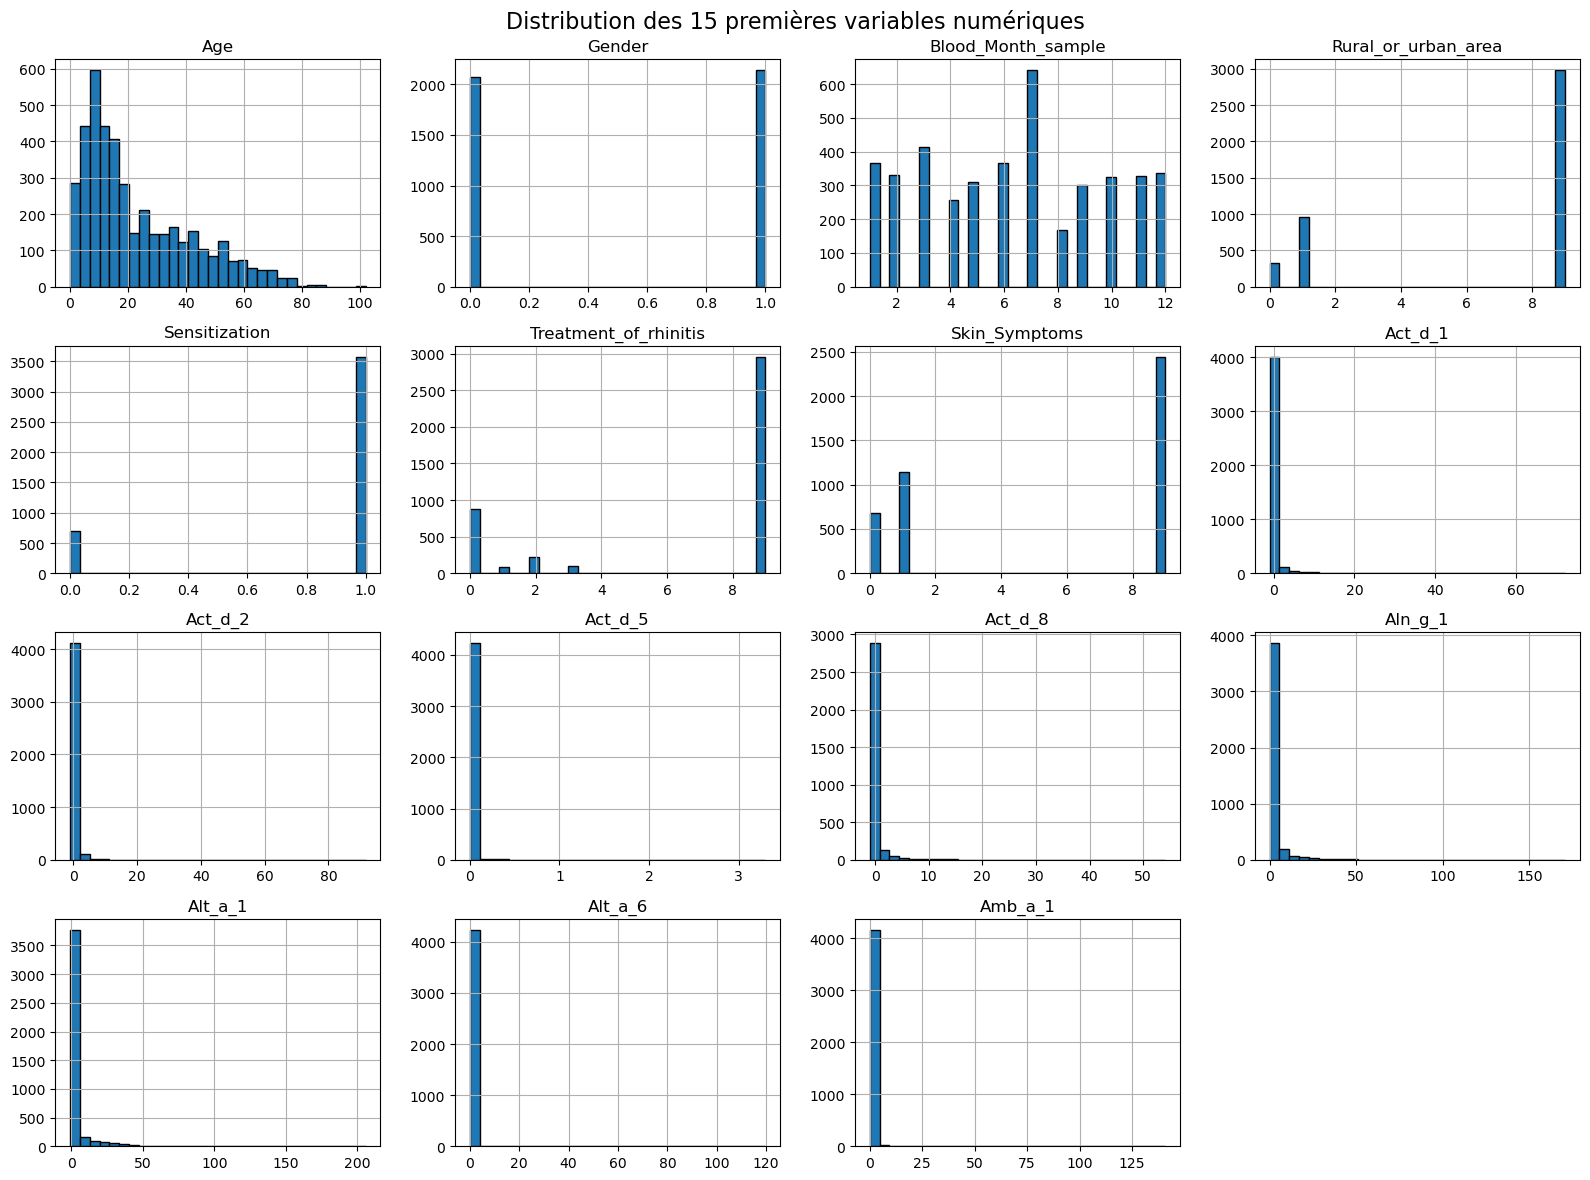

In [177]:
# Histogrammes des 15 premières variables numériques
variables = df_num.columns[:15]

df_num[variables].hist(
    figsize=(16, 12),
    bins=30,
    edgecolor="black"
)

plt.suptitle("Distribution des 15 premières variables numériques", fontsize=16)
plt.tight_layout()
plt.show()

**"Rural_or_urban_area" : 0 --> Rural, 1 --> Urbain**

**"Gender" : 0 --> femme, 1 --> Homme**

**"Skin_Symptoms" : 0 --> Non, 1 --> Oui**